/tmp/ipykernel_3667017/851001907.py:13: OptimizeWarning: Covariance of the parameters could not be estimated
  params, _ = curve_fit(


Fitting parameters: [0.75370332 0.99687498]


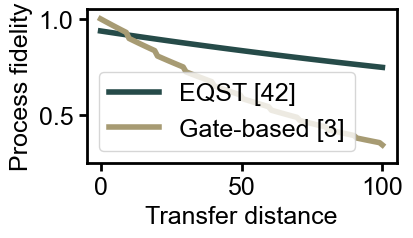

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

plt.rcParams["font.family"] = "arial"
plt.rcParams["font.size"] = 18

dist = [2, 5]
eqst_fide = [0.999, 0.992]
def eqst_fide_curve(x, A, P):
    return A * (P**x) + 0.25
params, _ = curve_fit(
    eqst_fide_curve,
    np.array(dist),
    np.array(eqst_fide),
    p0=[0.01, 0.01],
)
print("Fitting parameters:", params)

x_dist = np.linspace(0, 100, 100)
y_eqst = 0.983**4*eqst_fide_curve(x_dist, *params)
y_swap = 0.996**(2*(x_dist-x_dist//10))*0.983**(2*(x_dist//10))

fig, ax = plt.subplots(figsize=(4, 2))

for spine in ax.spines.values():
    spine.set_linewidth(2)
ax.tick_params(axis="both", width=2, length=6)

# plt.scatter(dist, 0.983**4*np.array(eqst_fide), color="red", marker="^", s=60, label="Empirical Result []")
plt.plot(x_dist, y_eqst, color="#264B49", linewidth=4, label="EQST [42]")
plt.plot(x_dist, y_swap, color="#A79B73", linewidth=4, label="Gate-based [3]")
plt.xlabel("Transfer distance")
plt.ylabel("Process fidelity")
plt.ylim(0.25, 1.05)
plt.legend()

os.makedirs("result/motivation/", exist_ok=True)
plt.savefig("result/motivation/fide_insight.svg", bbox_inches="tight")
# plt.close()

In [1]:
import os
import sys
sys.path.append("..")

from qunoc.utils.config import config
from qunoc.element.package import *
from qunoc.element.benchmark import *
from qunoc.routing.router import *

# config.debug_mapping = True
# config.debug_block = True
# config.debug_action = True

algo = "qaoa"
data_qubit_num = 400

result_dir = f"result/routing/example_{algo}_{data_qubit_num}"
os.makedirs(result_dir, exist_ok=True)

import logging
for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)
logging.basicConfig(
    filename=os.path.join(result_dir, "log.txt"),
    filemode='w',
    format="%(asctime)s - %(levelname)s - %(message)s",
    level=logging.INFO,
    encoding="utf-8"
)

package = Package.from_pickle(filepath="../evaluate/result/layout_scalability/package_size/40_40_greedy/package.pkl")
program = get_program(algo, data_qubit_num)

router = Router(package, program, result_dir=result_dir)
router.map_qubits()
print(f"Routing program {program.algo_name}-{program.data_qubit_num}")

router.compile_blocks_and_schedule_actions()
local_gate_num = 0
tele_gate_num = 0
for block in router.compute_blocks:
    if isinstance(block, LocalBlock):
        local_gate_num += 1
    elif isinstance(block, TeleBlock):
        if len(block.target_qubits) >= 2:
            tele_gate_num += len(block.target_qubits)
gate_num = program.gate_depend_graph.number_of_nodes()
print("Local gate: ", local_gate_num/gate_num, "Tele gate: ", tele_gate_num/gate_num)

Routing program qaoa-400
Local gate:  0.024059547379764918 Tele gate:  0.40427558206561237


In [2]:
import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)

from qunoc.element.package import *

result_dir = f"result/motivation/layout/wide"
os.makedirs(result_dir, exist_ok=True)

package = Package((100, 100), FabricateModel(), design_strategy="manual", result_dir=result_dir)
package.design_module_top_down(package.compute_modules[0], DesignTemplate.Radial, DesignOrientation.X, 30)
package.to_pickle(os.path.join(result_dir, "radial.pkl"))
fig = package.draw_qubits()[0]
fig.savefig(os.path.join(result_dir, "radial.png"), bbox_inches="tight")
print("Transfer performance:", package.estimate_transfer())

package = Package((100, 100), FabricateModel(), design_strategy="manual", result_dir=result_dir)
package.design_module_top_down(package.compute_modules[0], DesignTemplate.Grid, DesignOrientation.X, 49)
package.to_pickle(os.path.join(result_dir, "grid.pkl"))
fig = package.draw_qubits()[0]
fig.savefig(os.path.join(result_dir, "grid.png"), bbox_inches="tight")
print("Transfer performance:", package.estimate_transfer())



result_dir = f"result/motivation/layout/elongate"
os.makedirs(result_dir, exist_ok=True)

package = Package((100, 40), FabricateModel(), design_strategy="manual", result_dir=result_dir)
package.design_module_top_down(package.compute_modules[0], DesignTemplate.Grid, DesignOrientation.X, 19)
package.to_pickle(os.path.join(result_dir, "grid.pkl"))
fig = package.draw_qubits()[0]
fig.savefig(os.path.join(result_dir, "grid.png"), bbox_inches="tight")
print("Transfer performance:", package.estimate_transfer())

package = Package((100, 40), FabricateModel(), design_strategy="manual", result_dir=result_dir)
package.transfer_lines = [TransferLine(1, 99, (0, True), (39, True))]
package.compute_modules = [ComputeModule(0, 0, package.transfer_lines[0], 39)]
package.design_tree_root = Node(package.compute_modules[0])
package.design_tree_dict = {str(package.compute_modules[0]): package.design_tree_root}
for area in package.compute_modules + package.transfer_lines:
    package.complete_area(area)
package.complete_package()
package.design_module_top_down(package.compute_modules[0], DesignTemplate.Stripe, DesignOrientation.X, 13)
package.to_pickle(os.path.join(result_dir, "stripe.pkl"))
fig = package.draw_qubits()[0]
fig.savefig(os.path.join(result_dir, "stripe.png"), bbox_inches="tight")
print("Transfer performance:", package.estimate_transfer())



result_dir = f"result/motivation/layout/narrow"
os.makedirs(result_dir, exist_ok=True)

package = Package((40, 40), FabricateModel(), design_strategy="manual", result_dir=result_dir)
package.transfer_lines = [TransferLine(1, 39, (0, True), (39, True))]
package.compute_modules = [ComputeModule(0, 0, package.transfer_lines[0], 39)]
package.design_tree_root = Node(package.compute_modules[0])
package.design_tree_dict = {str(package.compute_modules[0]): package.design_tree_root}
for area in package.compute_modules + package.transfer_lines:
    package.complete_area(area)
package.complete_package()
package.design_module_top_down(package.compute_modules[0], DesignTemplate.Stripe, DesignOrientation.X, 9)
package.to_pickle(os.path.join(result_dir, "stripe.pkl"))
fig = package.draw_qubits()[0]
fig.savefig(os.path.join(result_dir, "stripe.png"), bbox_inches="tight")
print("Transfer performance:", package.estimate_transfer())

package = Package((40, 40), FabricateModel(), design_strategy="manual", result_dir=result_dir)
package.design_module_top_down(package.compute_modules[0], DesignTemplate.Radial, DesignOrientation.X, 10)
package.to_pickle(os.path.join(result_dir, "radial.pkl"))
fig = package.draw_qubits()[0]
fig.savefig(os.path.join(result_dir, "radial.png"), bbox_inches="tight")
print("Transfer performance:", package.estimate_transfer())

Transfer performance: (0.4337716339648873, 0.16837605757020188)
Transfer performance: (0.2992503066802351, 0.18241123846505436)
Transfer performance: (0.635596323967323, 0.12845844089453204)
Transfer performance: (0.5184805387788218, 0.17427738485506775)
Transfer performance: (0.7162733753831896, 0.10268873181411164)
Transfer performance: (0.6956780143595095, 0.11016820671759751)


In [3]:
# Transfer performance: (0.4337716339648873, 0.16837605757020188)
# Transfer performance: (0.2992503066802351, 0.18241123846505436)
# Transfer performance: (0.635596323967323, 0.12845844089453204)
# Transfer performance: (0.5184805387788218, 0.17427738485506775)
# Transfer performance: (0.7162733753831896, 0.10268873181411164)
# Transfer performance: (0.6956780143595095, 0.11016820671759751)

wide_fide_improve = 0.4337716339648873 - 0.2992503066802351
wide_iso_improve = (0.18241123846505436 / 0.2992503066802351) / (0.16837605757020188 / 0.4337716339648873)
elongate_fide_improve = 0.635596323967323 - 0.5184805387788218
elongate_iso_improve = (0.17427738485506775 / 0.5184805387788218) / (0.12845844089453204 / 0.635596323967323)
narrow_fide_improve = 0.7162733753831896 - 0.6956780143595095
narrow_iso_improve = (0.11016820671759751 / 0.6956780143595095) / (0.10268873181411164 / 0.7162733753831896)
print(wide_fide_improve, wide_iso_improve)
print(elongate_fide_improve, elongate_iso_improve)
print(narrow_fide_improve, narrow_iso_improve)

0.13452132728465221 1.5703548480823055
0.11711578518850119 1.6631342402095601
0.020595361023680092 1.1045974073768265
